## **Introduction**


---


> In this module, we will use a solubility dataset to classify organic compounds using physicochemical characteristics such as : Topological polar surface area, molecular weight, and octanol-water partition coefficient. We will begin by understanding the basics of a supervised classification model: how it works, how it classifies classes, and how to evaluate it, using Python and its libraries. We will start with our first model: K-nearest neighbors. To understand the main objective of this education module, we will begin by learning what machine learning is.



> Machine learning (ML) is defined as the ability of a computer to learn without being explicitly programmed. Specifically, it is given data it can learn from, so it can identify existing patterns and apply them to make predictions and assumptions. A key characteristic of ML is self-learning, which means applying statistical modeling to detect patterns and improve performance based on data and empirical information, without direct programming commands. However, this doesn’t mean machines can make decisions without any upfront programming. On the contrary, machine learning is heavily dependent on code input. The key takeaway is that these models can perform tasks using input data rather than relying on direct commands.






### What is a supervised machine learning model?


---

>In order to understand many of the possible machine learning models available to use, we need to make a distinction between supervised and unsupervised machine learning. Firstly, supervised machine learning is when the data being given to the algorithm is data that has been verified, and its output/result is known already, to be used as comparison. In the other hand unsupervised learning is when the output is not known. Additionally, in some cases there's a mixture of both these practices in learning models, this being when data sets are utilized where in some parts only the output is known; this is known as semi-supervised machine learning.

### What is classification and regression?


---

There are two main types of supervised machine learning: regression and classification. Regression is utilized when the output that is needed is a continuous numerical value. Meanwhile, classification is trained to strictly classify. For example, if there were two algorithms for determining temperature in a solution, and one was returning an output of “100 Fahrenheit approx..” and the other returns an output of “mildly hot”.


## ⚙ **DataSet**
---
For this demonstration, we will use a curated subset of 300 molecules selected from the original AqSolDB dataset.

The full AqSolDB dataset contains thousands of compounds, which is useful for larger machine learning studies but can make an introductory activity more difficult to explore and visualize.

To keep this module more concise and easier to follow, the dataset was reduced to 300 molecules while maintaining a balanced representation of the solubility classes and including compounds that are more familiar in an introductory organic chemistry context.

This smaller dataset allows us to focus on understanding the KNN workflow, feature selection, model evaluation, and interpretation without being overwhelmed by the size of the original dataset.








### Loading the DataSet


---




> The curated dataset can be loaded directly into Google Colab running the following cell:






In [ ]:
import pandas as pd

url ="https://raw.githubusercontent.com/YadielCruz/IRML-CER3D-module-code/refs/heads/main/AqSolDB_300_Organic_Course_Molecules.csv"

## Exploring the Dataset


---


Before building our machine learning model, we need to explore and understand the chemical information in the dataset we will use for prediction.
The first step in this exploratory analysis is to load the dataset into a DataFrame, which is a table-like data structure provided by the pandas library.
First, import pandas using the standard abbreviation pd:


```
import pandas as pd
```



Next, use the read_csv() function to read the dataset file stored in the variable path and save it as a DataFrame named df:



```
df = pd.read_csv(url)
```


The variable df now contains the dataset in a table format that can be explored and analyzed using pandas.

To preview the first few rows of the dataset, use the .head() method:



```
df.head()
```



This allows us to quickly inspect the structure of the dataset, including its columns, chemical descriptors, and target information.

*Now try it yourself! Try to see what type data holds each column*




In [ ]:
#Code here!
#--------------------------------
df = pd.read_csv(url)
#--------------------------------

## Identifying Features


---

In machine learning, features are the measurable characteristics or properties a model uses to describe each observation in a dataset. In a chemical dataset, features can include molecular descriptors such as molecular weight, lipophilicity, number of aromatic rings, or molecular surface area. For a K-Nearest Neighbors (KNN) model, features matter because the algorithm classifies a new observation based on its distance from previously labeled observations. Each feature contributes to a data point’s position in the feature space. The choice of features can strongly influence model performance. Features that contain useful information about the target variable can help separate the different classes, while irrelevant or redundant features may introduce noise and make distance calculations less informative.

To determine the best molecular descriptors or features for our model, we will base our selection on the following criteria:

1. **Is the variable a molecular descriptor?**

> This question, although it may seem simple, is very important, as not every column in the dataset describes a molecular property. Some variables contain identification or source-related information, telling where the data came from or how the molecule is labeled.



> Moreover, descriptors that do not represent numbers are, for the moment, not viable for use in our model, as it operates using a coordinate system in numerical format, not text.

2. **Is the descriptor chemically relevant for determining the solubility of a molecule in water?**

> In this question, we want to identify which descriptors represent molecular properties relevant to describing its water solubility.
Examples of these descriptors are MolLogP, MolWt, TPSA, NumHDonors, NumHAcceptors, NumRotatableBonds, NumAromaticRings, RingCount, MolMR, and LabuteASA.
> These descriptors provide useful information about a molecule’s properties that can be related to its solubility in water. Specifications for these descriptors are shown in the table below.

3. **Does the descriptor have redundant information compared to another descriptor?**

> Two or more molecular descriptors may contain similar information about aqueous solubility. If molecular descriptors are highly correlated, the same information may be counted more than once when the KNN model calculates the distance between molecules. For this reason, highly correlated descriptors should be compared, and one may be removed if both provide nearly the same information.



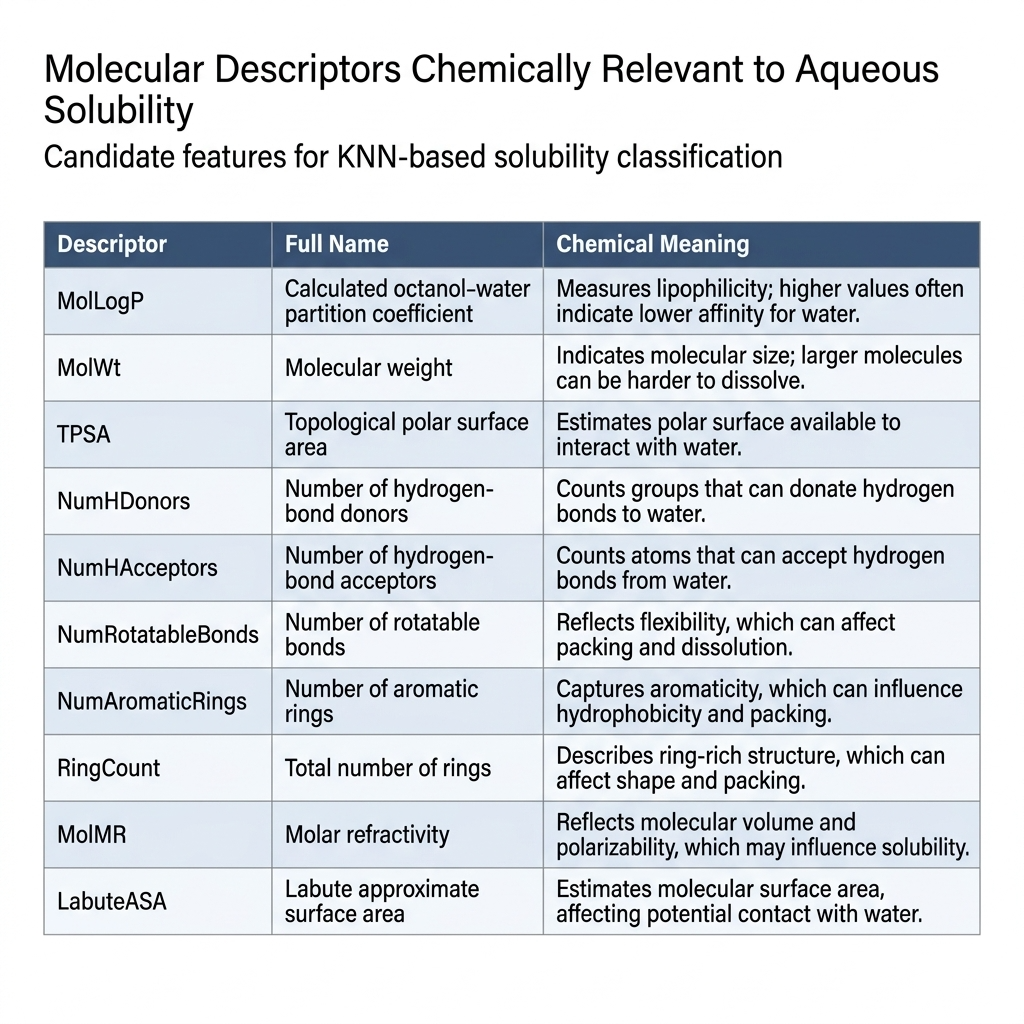

### Selecting the Columns for the Model

The first step in selecting our features is to filter the dataset by removing the variables that do not satisfy **Question 1**. Since only a few columns do not meet the requirements, we will create a new DataFrame named model_df to store the columns that weren't removed. In pandas, the .drop() method can be used to remove specific columns from a DataFrame.

For example:
```
model_df = df.drop(columns=["Column1","Column2","Column3"])
```
We will start by removing the two descriptors SMILES and ID, since they are not included among the molecular descriptors selected in the table above. At the same time, we will keep the columns associated with solubility because they will later be used to define the target variable for the classification model. Before removing any columns, we first need to identify their exact names in the dataset. To do this, we can use the pandas .columns attribute, which returns the names of all columns present in the original DataFrame.

```
df.columns
```

Once we identify the column names, we can create a new DataFrame containing only the descriptors we want to keep:

```
model_df = df.drop(columns=["Column1","Column2"])
```

The new DataFrame, *model_df*, now contains only the molecular descriptors and target variables selected for the analysis.

We can then preview this new dataset by using the pandas .head() method described previously.


```
model_df.head()
```

Creating a new DataFrame makes it easier to organize the variables that will be used in the machine learning model while keeping the original dataset unchanged.


---




*Now it’s your turn to create the new DataFrame. Use the column names identified with df.columns and drop only the molecular descriptors that aren’t listed in the table above. Do not drop the solubility-related columns, as they will be our target variables. Store the new DataFrame in a variable named model_df. Then use model_df.head() to verify that your new DataFrame contains the correct columns.*





Index(['ID', 'Name', 'SMILES', 'Solubility', 'Solubility_Class', 'MolWt',
       'MolLogP', 'NumHAcceptors', 'NumHDonors', 'NumRotatableBonds',
       'NumAromaticRings', 'RingCount', 'TPSA', 'LabuteASA'],
      dtype='object')


<Axes: title={'center': 'Correlation Matrix of Molecular Descriptors'}>

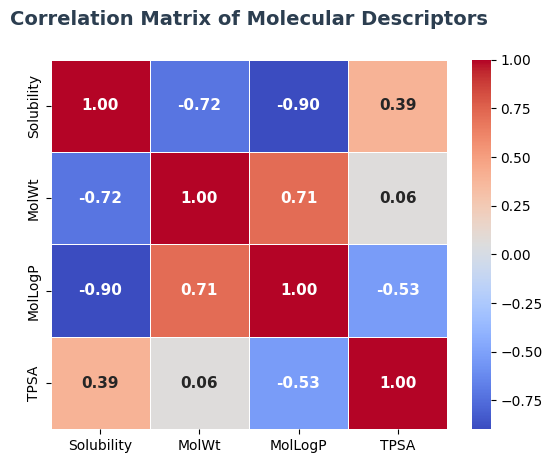

In [ ]:
#Code here!
#--------------------------------
import seaborn as sns
import matplotlib.pyplot as plt
print(df.columns)

model_df = df.drop(columns = ['ID', 'SMILES'])

model_df.head()

fmodel=model_df[['Solubility','MolWt','MolLogP','TPSA']]
df_corr=fmodel.corr()

plt.title('Correlation Matrix of Molecular Descriptors', fontweight='bold', fontsize=14, pad=25, color='#2c3e50')


sns.heatmap(df_corr,annot=True,cmap="coolwarm",fmt=".2f",
    annot_kws={'weight': 'bold', 'size': 11},
    linewidths=0.5)

#--------------------------------



---

Finally, we will examine each molecular descriptor to identify which features are most useful for distinguishing between the different solubility classes. Our identification should be based on Question 2 and Question 3

To do this, we will compare the descriptors with each other and with the solubility information contained in the dataset. This will help us identify descriptors that may contain useful chemical information, as well as descriptors that may provide very similar or redundant information.

One simple way to begin this analysis is by calculating the correlation between the numerical variables in the dataset. Correlation allows us to observe whether two variables tend to increase or decrease together.

The best way to compare correlations among molecular descriptors is to use a correlation heatmap. The heatmap lets us visualize these relationships more effectively. Below, you can visualize an already calculated heatmap.


---





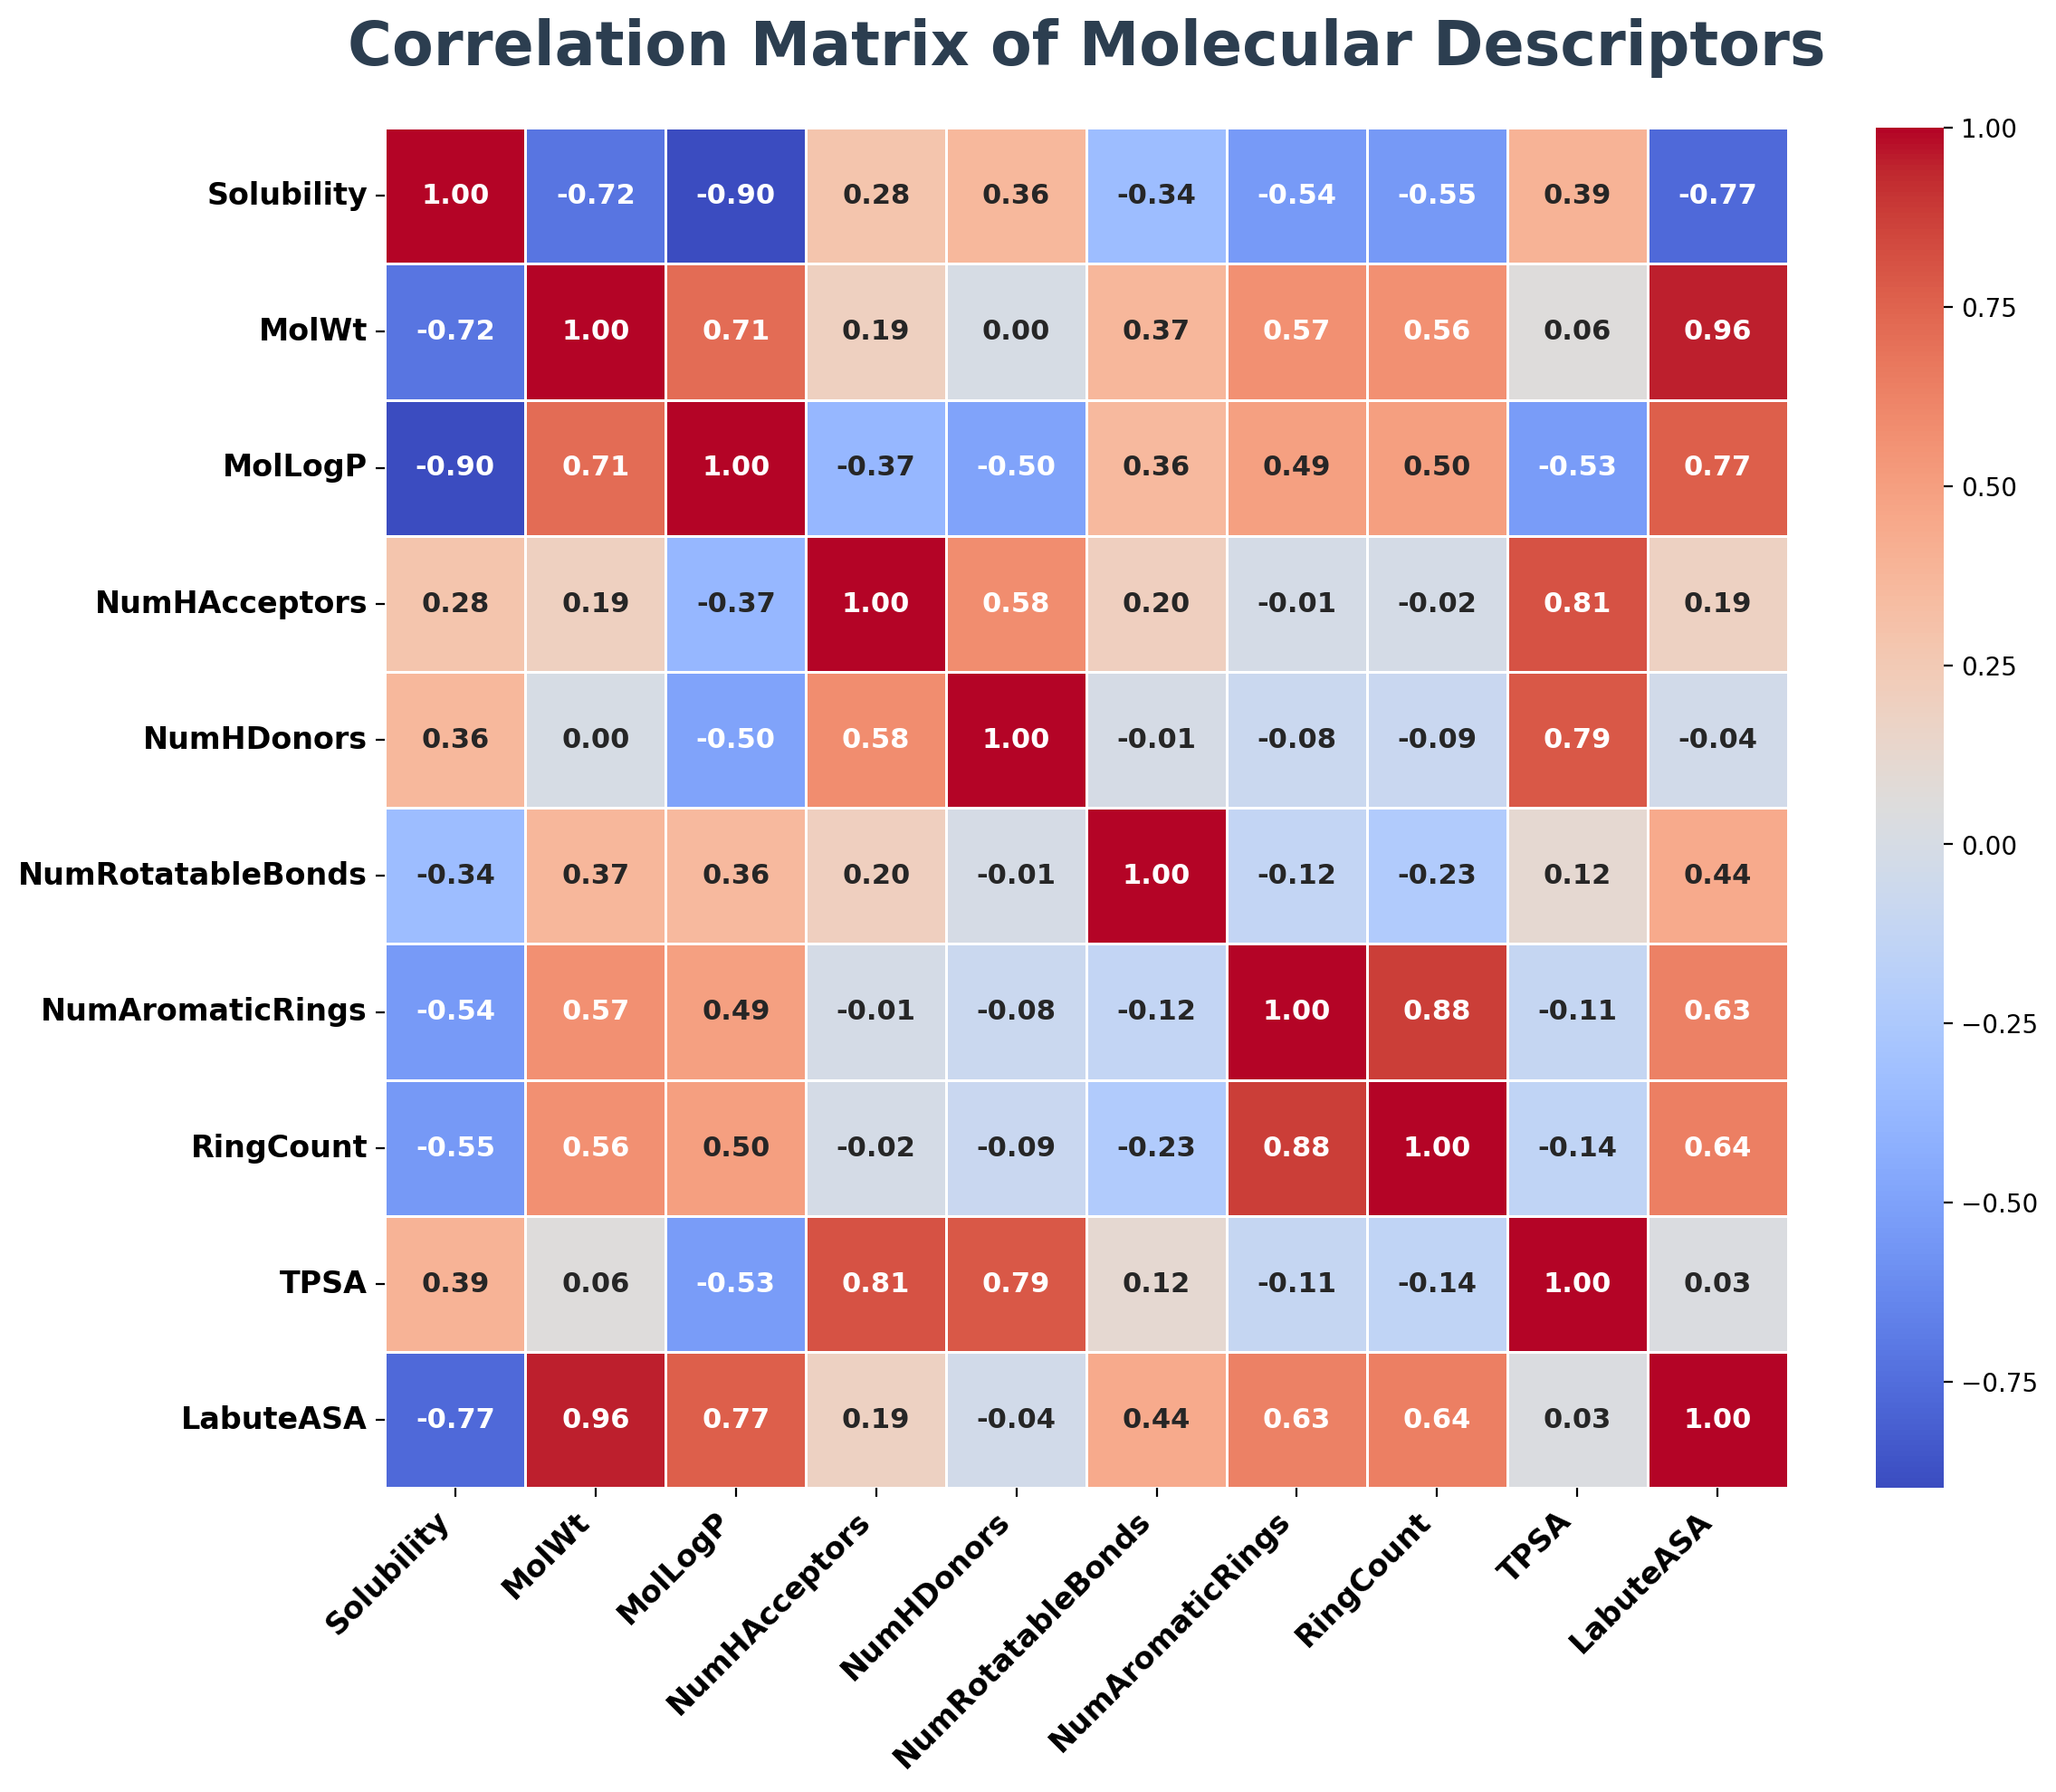


***How to read a correlation heatmap:***

-	Correlation values will range between -1 and +1.
-	Values close to +1 will indicate a strong proportional/positive relationship. As one variable tends to increase, the other will increase as well.
-	Values close to -1 indicate a strong inverse proportion/negative relationship. As one variable increase, the other will decrease.
-	Values close to 0 indicate little or no linear relationship between the variables.






---
**Selecting the Final Molecular Descriptors**
---


Although several molecular descriptors may be used in the final KNN model, only three can be displayed simultaneously in a three-dimensional visualization. For this reason, we will use MolLogP, MolWt, and TPSA to represent the molecular feature space.

These descriptors were selected because they describe different molecular properties and also show meaningful relationships with solubility:

- MolLogP represents lipophilicity and shows a strong negative correlation with solubility (r = -0.90). This means that, in this dataset, molecules with higher MolLogP values tend to have lower aqueous solubility.

- MolWt represents molecular size and also shows a negative correlation with solubility (r = -0.72). In general, larger molecules in this dataset tend to be less soluble in water.

- TPSA represents molecular polarity and shows a positive correlation with solubility (r = 0.39). Molecules with larger polar surface areas tend to show somewhat higher aqueous solubility.

It is also important to compare the descriptors with each other. MolWt and MolLogP show a moderate positive correlation (r = 0.71), while MolLogP and TPSA show a moderate negative correlation (r = -0.53). MolWt and TPSA show almost no linear correlation (r = 0.06).

This combination therefore provides three chemically meaningful dimensions-size, lipophilicity, and polarity-without selecting descriptors that are almost identical to one another.

The three-dimensional visualization will help us observe how compounds are distributed in feature space. However, this visualization does not determine which features must be used in the final KNN model.

____




## **Visualizing our descriptors**


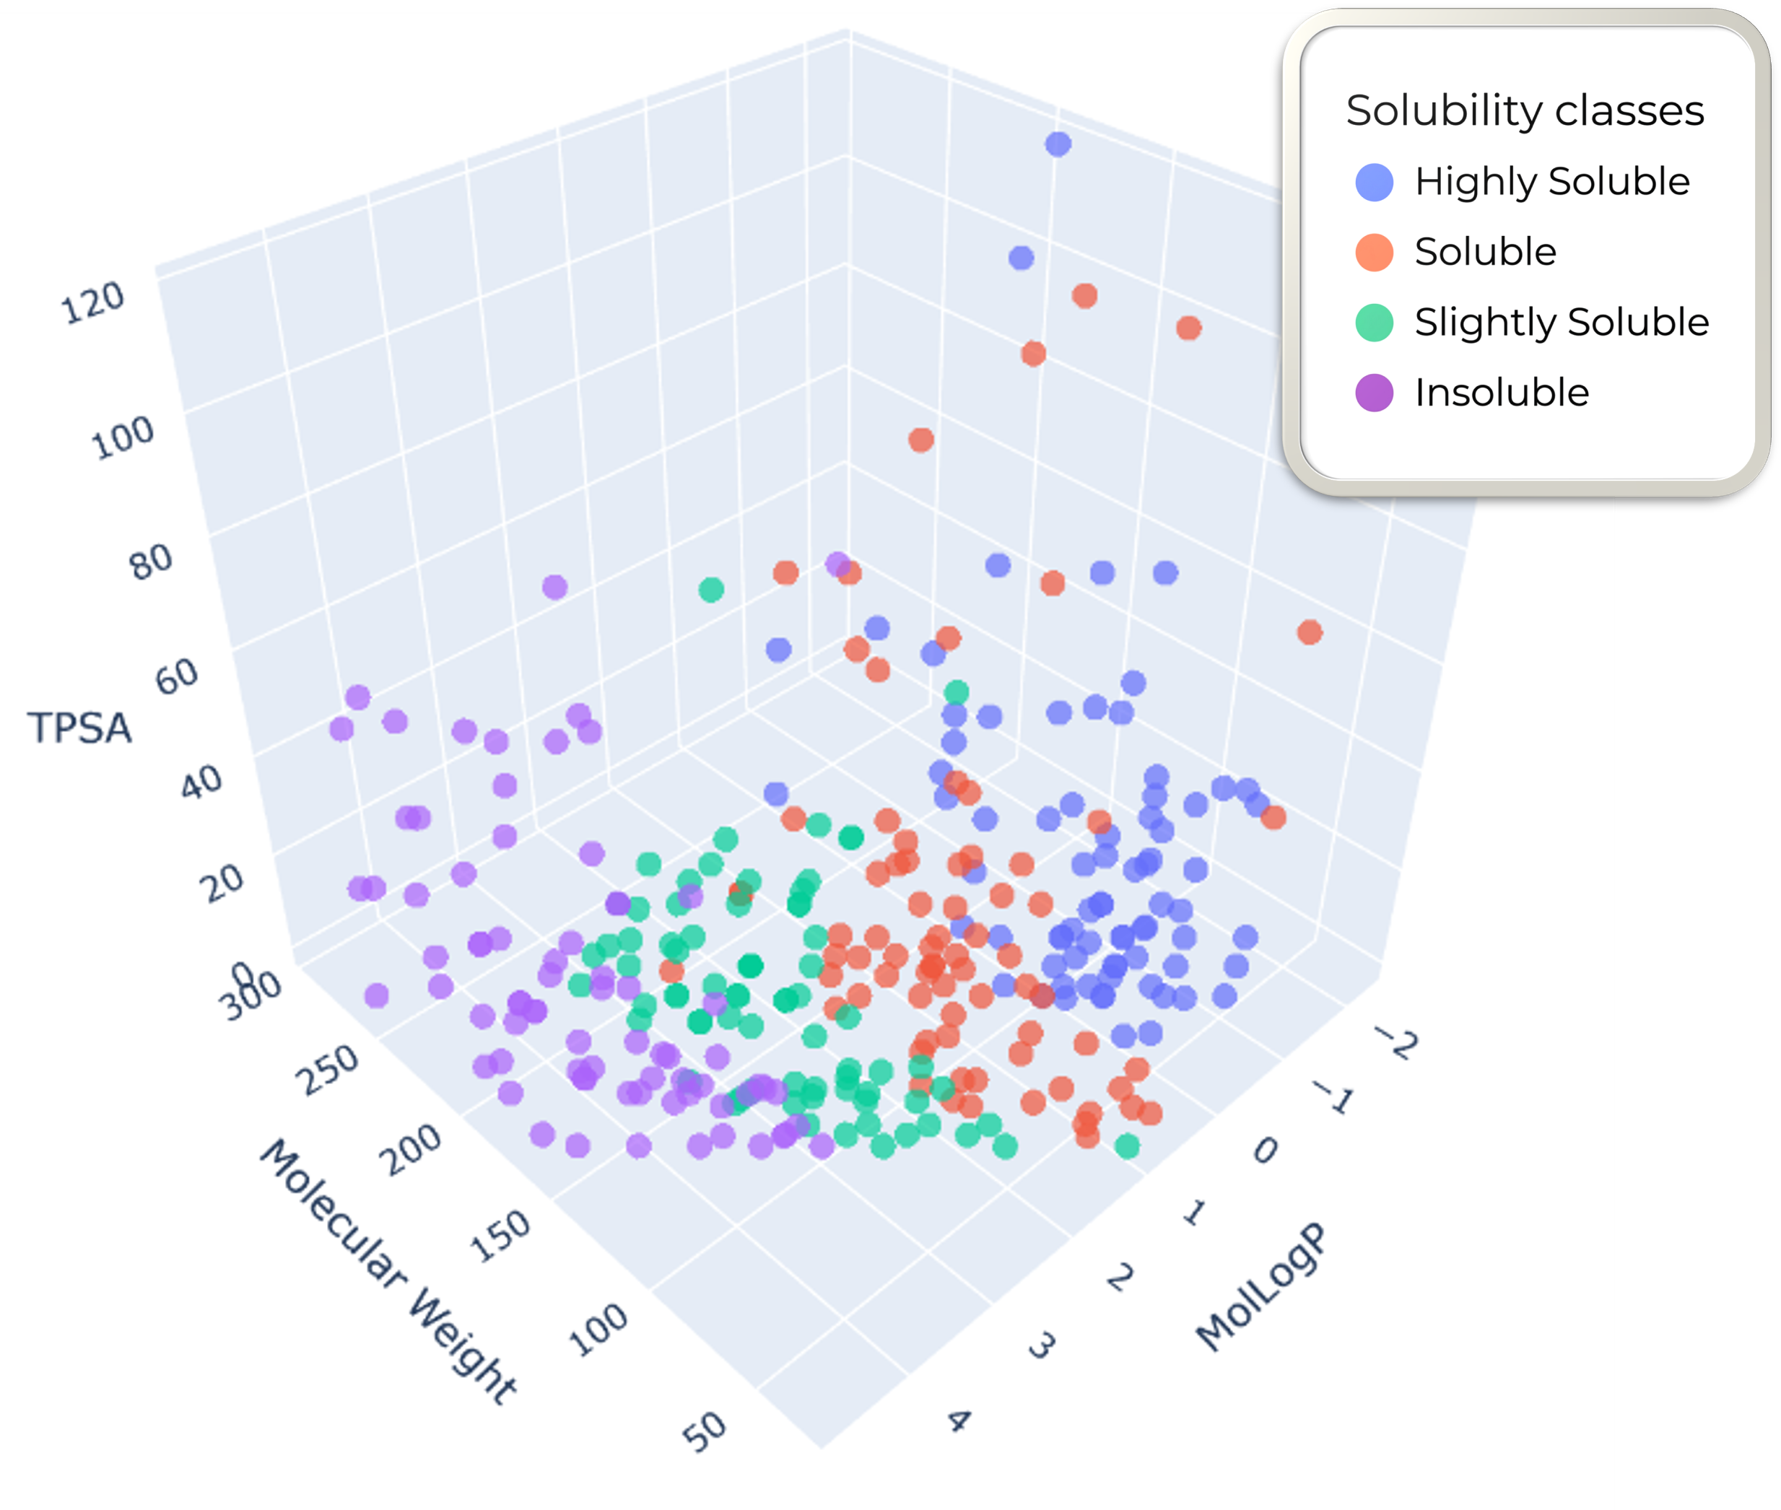

To better understand how the selected molecular descriptors represent each compound, we can visualize three features simultaneously in a three-dimensional scatter plot. Each point in the graph represents one molecule in the dataset. Its position is determined by its values for these three molecular descriptors, while the color represents its aqueous solubility class. This type of visualization allows us to observe how molecules with different solubility classes are distributed throughout the molecular feature space.

From the plot, we can observe that some solubility classes tend to occupy different regions of the feature space. However, there is also considerable overlap between the classes. This overlap indicates that the selected descriptors do not completely separate the solubility groups, which makes the classification problem more realistic.

The KNN algorithm will later use distances within this feature space to identify molecules with similar characteristics and predict the solubility class of new observations.



_____
### Target Variable

In machine learning, the value that we want the model to predict is called the target variable. You may have noticed that the new dataset contains two columns related to each molecule's aqueous solubility. The *Solubility* column contains the numerical solubility value, while the *Solubility_Class* column contains the categorical class assigned to each molecule. For this KNN classification model, *Solubility_Class* will be used as the target variable, since the goal of the model is to predict the solubility class of a molecule based on its molecular descriptors.

Specifically, we want our model to classify the molecules into 1 of 4 classes. Each class is meant to describe how soluble a specific molecule is in water. The determination of these classes was solely based on their solubility value (LogS);

- Molecules with solubility values of 0 or higher are classified as Highly Soluble.

- Molecules with solubility values between 0 and -2 are classified as Soluble.

- Molecules with solubility values between -2 and -4 are classified as Slightly Soluble.

- Molecules with solubility values below -4 are classified as Insoluble.


These criteria were determined based on the information given in the original AqSolDB dataset. In our dataset, we possess a total of 300 compounds divided into these four groups. There are 75 molecules in each group.






## Knn Model


---


> In this module, we will use a classification model named k-nearest neighbors. This model can classify unknown data points based on their proximity to known data points. This classification depends on a hyperparameter called “k”. This hyperparameter determines the k number of data points closest to the target data point. If we set k to 3, as seen in Figure below, the k-NN model analyses the 3 nearest data points to determine which class the new data point belongs to. This model's classification technique is sometimes referred to as a “memory-based procedure” because it uses all training data each time it makes a prediction. For this reason, it isn’t recommended for making predictions on large datasets where multiple distances in high-dimensional data are measured. When you need to analyze high-dimensional datasets, you can use dimensionality reduction algorithms such as PCA (Principal Component Analysis), the most common for this type of analysis. In this module, we will stick to low-dimensional data points (3D), for which PCA will not be necessary.





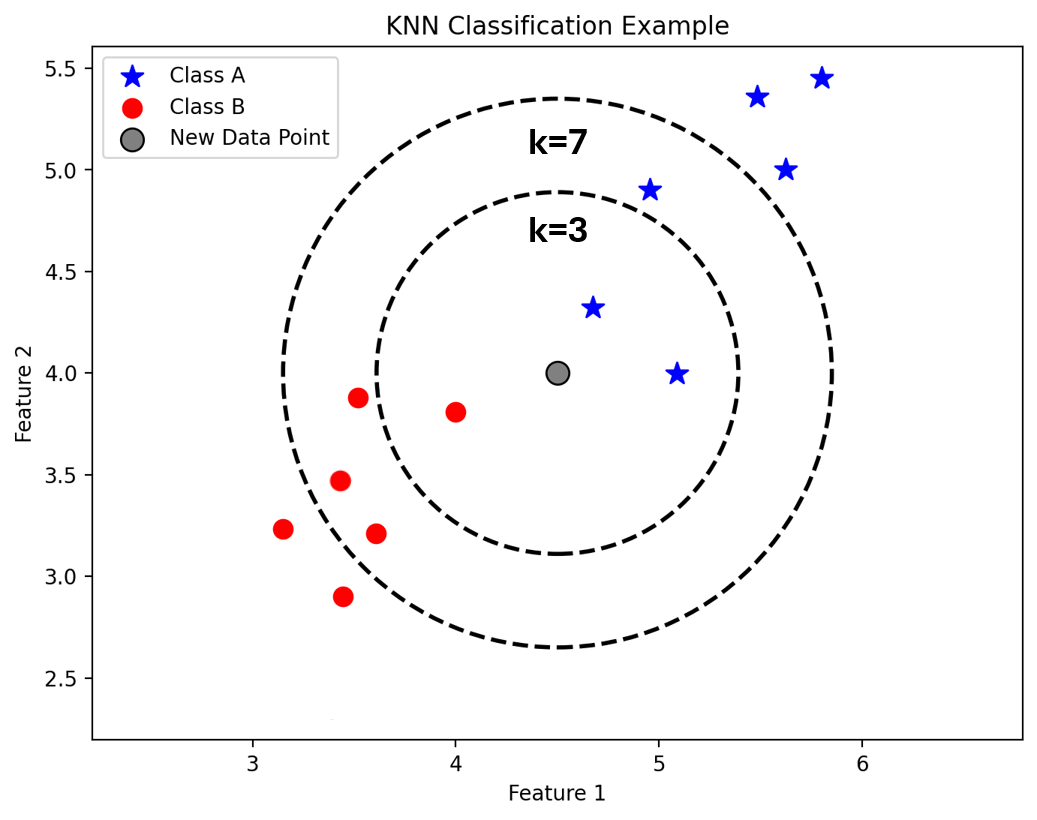

## Splitting the Dataset into Training and Testing Sets



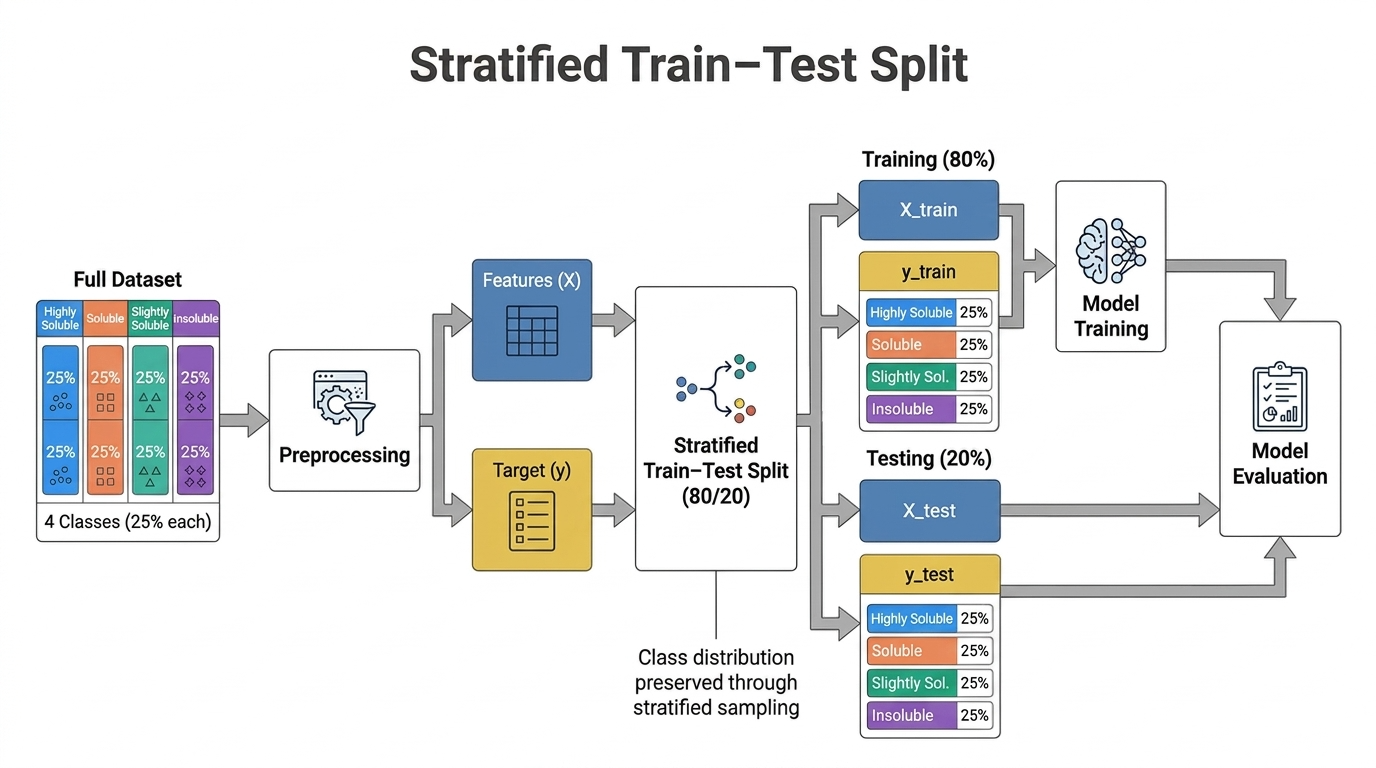

A train-test split is a machine learning technique that divides a dataset into training and testing sets to evaluate how well a model generalizes to new data.

A goal of supervised learning is to build a machine learning model that performs well on unseen data. If you have new data, it’s a good idea to see how your model performs on it. This is why we will not train our model with all 300 molecules. Instead, we will split the dataset into two parts: a training set and a testing set.

We can do this using the train_test_split() function from sklearn.model_selection. We can import this function from sklearn as shown below.



```
from sklearn.model_selection import train_test_split
```

Because our dataset contains four solubility classes, we want both the training and testing sets to maintain approximately the same class distribution as the original dataset. Because we want to make our split with an equal distribution of classes, we will also use the stratify parameter.

The following code shows how to make a stratified train-test split, splitting our data into 80% for training and 20% for evaluation.


```
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
```

The split will be stored in four variables:

- X_train: contains the molecular descriptors used to train the model.

- X_test: contains the molecular descriptors reserved for final evaluation.

- y_train: contains the solubility classes corresponding to the training data.

- y_test: contains the solubility classes corresponding to the testing data.

**The variable X in the parameters will be a list of the features we identified previously, and y will be the target variable.**

Using *stratify=y* tells train_test_split() to preserve the proportion of each solubility class when dividing the data. In our dataset, since we have 300 molecules, using a 20% test set gives approximately 60 molecules for testing and 240 molecules for training the model. Each class will contribute approximately the same proportion of molecules to both the training and testing sets.

In addition, the original dataset contains 75 molecules in each solubility class; the stratified split should preserve the same class proportions in both datasets.

You should obtain approximately:

- Training set: 60 molecules per class

- Testing set: 15 molecules per class



**What do the other parameters mean?**

test_size=0.20 reserves 20% of the dataset for testing.

random_state=42 makes the random split reproducible, meaning that the same observations will be assigned to the training and testing sets each time the notebook is run.




---


### **Your Turn: Create the Train-Test Split**

Now it is your turn to divide the dataset into training and testing sets.

Use the train_test_split() function from sklearn.model_selection and create the following four variables:

X_train

X_test

y_train

y_test

For this module:

Use 80% of the data for training

Use 20% of the data for testing

Set random_state=42 so the split can be reproduced

Use stratify=y so that the four solubility classes remain equally represented in both the training and testing sets

---

In [ ]:
#Code here!
#--------------------------------
from sklearn.model_selection import train_test_split

X = model_df[['MolWt','MolLogP','TPSA']]
y = model_df['Solubility_Class']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
#--------------------------------

## **Feature Scaling**

Before using the Knn model to calculate distances and make predictions, we must consider an important issue: the three descriptors have very different numerical scales. This leads us to the next step, **feature scaling**.

Feature Scaling is a preprocessing technique used in machine learning to place numerical features on comparable scales. This step is important because datasets may contain features with very different units and numerical ranges, just like the molecular descriptors in our dataset.

For example, the molecular weight (MolWt) descriptor contains values ranging in the hundreds, while the octanol-water partition coefficient (MolLogP) contains values ranging from -2 to 5. Although both descriptors may be important for predicting aqueous solubility, their numerical scales are very different. This is why feature scaling is important; it can prevent this problem by placing the descriptors on similar scales. Distance-based machine learning algorithms such as KNN are particularly sensitive to feature scales. Therefore, scaling the molecular descriptors before training the model allows the calculated distances to reflect bigger differences between molecules rather than differences in measurement scale.

An important clarification is that our goal in feature scaling is not to make every molecular descriptor equally important; that's for the model to decide. Instead, we want to prevent a descriptor's units or numerical range from determining its influence on the model.



---
**Applying Feature Scaling with StandardScaler**
---

Now that we understand why feature scaling is important for KNN, let's prepare to apply it to our molecular descriptors, specifically to our splitted data.

For this module, we will use StandardScaler from the sklearn.preprocessing library. StandardScaler transforms each feature so that it is centered around a mean of approximately 0 and has a standard deviation of approximately 1.

This places descriptors with very different numerical ranges on a comparable scale.


---
**Your Turn: Import the Scaler**

StandardScaler is available in the sklearn.preprocessing module.

The following code shows how to import and store:


```
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
```

Once created the variable scaler, it will contain the instructions needed to determine how each molecular descriptor should be transformed.

Now complete the following steps:

1. Use .fit_transform() on X_train.

2. Store the scaled training data in a variable named X_train_scaled.

3. Use .transform() on X_test.

4. Store the scaled testing data in a variable named X_test_scaled.



In [ ]:
#Code here!
#--------------------------------
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

X_train_scaled[:5]
#--------------------------------

array([[ 2.41922607,  1.45978259,  1.11962824],
       [ 1.86238955,  1.47069002,  0.16673726],
       [-0.71648216, -0.67096816,  0.65930309],
       [-0.82158891,  0.16555935, -1.01094284],
       [ 0.62553352,  0.42857354,  0.65930309]])

### **Why do we use two different methods?**

Using the method *.fit_transform()*, is essential on training data because the scaler must first calculate the mean and standard deviation of each feature before transforming the values. On the other hand, *.transform()* is used on the testing data because we want to apply the same scaling learned from the training data without allowing the scaler to learn any information from the test set. This helps prevent data leakage and keeps the test data truly unseen during model preparation.

## Training the K-Nearest Neighbors Model



It is finally time to train the K-nearest neighbor classification model. Up to this point, we have prepared the dataset by selecting the molecular descriptors, separating the features and target variable, creating the training and testing sets, and scaling the numerical features.

At this stage, the data should be ready to be given to the model for training. Specifically, we will use the variables X_train_scaled and y_train. The model will use these features and classes to learn how molecules with different properties are distributed among the four aqueous solubility classes.



---


**Your Turn: Create the Knn Classification model.**


First we willl import the model from *sklearn.neighbors*:



```
from sklearn.neighbors import KNeighborsClassifier
```
 We will then create the model and we will choose the number of k (nearest neighbor), that the model will consider when making the prediction.



```
knn = KNeighborsClassifier(n_neighbors=k)
```
For now we can start by using k=3. We will later investigate ich valuee of k will be the best at predicting.


Finally, we will train the model by using the scaled training features and their corresponding solubility classes:


```
knn.fit(X_test, y_test)
```
The .fit() method gives the training data to the KNN model. KNN stores these observations and later compares new molecules with them to find the closest neighbors and predict their solubility class.


---


*Build your model!*


In [ ]:
#Code here!
#--------------------------------
from sklearn.neighbors import KNeighborsClassifier

k=3
knn = KNeighborsClassifier(n_neighbors=k)

knn.fit(X_test, y_test)
#--------------------------------

KNeighborsClassifier(n_neighbors=3)

## Evaluating your model

Now that the KNN model has been trained, we need to evaluate how well it performs on data that it has not seen before. For this, we will use the testing set. First, we will use the trained model to predict the solubility classes of the scaled testing data:



```
y_pred = knn.predict(X_test)
```
The variable y_pred will store the solubility class predicted by the KNN model for each molecule in the testing set.




In [ ]:
#Code here!
#--------------------------------

y_pred = knn.predict(X_test)

#--------------------------------

---

## **Accuracy**

One of the simplest ways to evaluate a classification model is to determine the model's accuracy. Accuracy represents the proportion of predictions that were classified correctly. In other words, out of 60 molecules, how many did the model classify correctly? In order to determine this, we will first import the accuracy_score:



```
from sklearn.metrics import accuracy_score
```

Then calculate the accuracy:


```
accuracy = accuracy_score(y_pred, y_test)
```
The accuracy_score() function requires two main inputs:

- y_test contains the actual solubility classes of the molecules in the testing set.

- y_pred contains the solubility classes predicted by the KNN model.

Finally, display the result:



```
print("Accuracy:", accuracy)
```

---
*Your turn!*

In [ ]:
#Code here!
#--------------------------------

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_pred, y_test)

print("Accuracy:", accuracy)

#--------------------------------

Accuracy: 0.8333333333333334


### Congratulations!

You have completed the **KNN classification demo**.

You prepared the data, scaled the features, trained the model, made predictions, and evaluated its accuracy.

Now, feel free to experiment with different values of `k` and see which value gives the best result.

```python
knn = KNeighborsClassifier(n_neighbors=k)
```

Try values such as `1, 3, 5, 7, 9, 11`, and compare the accuracy.